In [2]:
# XGBoost Classifier
# Train an optimized gradient boosting model for binary classification.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from xgboost import XGBClassifier

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create XGBoost model
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_child_weight=1,
    gamma=0,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0,
    reg_lambda=1,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

Accuracy: 0.956140350877193

Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



<Figure size 1000x700 with 0 Axes>

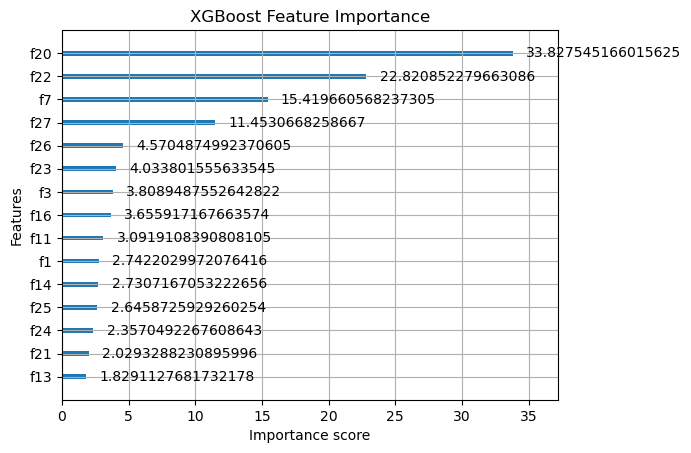

In [3]:
# XGBoost Feature Importance
# Visualize the most important features used by the trained model.

from xgboost import plot_importance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plot_importance(
    model,
    importance_type="gain",
    max_num_features=15
)

plt.title("XGBoost Feature Importance")
plt.show()

In [4]:
# XGBoost Hyperparameter Tuning
# Search for a good combination of XGBoost parameters using cross-validation.

from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

xgb = XGBClassifier(
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "gamma": [0, 0.1, 0.3, 0.5],
    "reg_lambda": [1, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Accuracy:")
print(random_search.best_score_)

# Final test evaluation
best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

print("\nTest Accuracy:")
print(accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 1.0}

Best CV Accuracy:
0.9780219780219781

Test Accuracy:
0.9473684210526315


Exception ignored in: <function ResourceTracker.__del__ at 0x102b19bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x107871bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104c7dbc0>
Traceback (most recent call last

### binary classification 

In [5]:
# XGBoost Binary Classification
# Train, predict probabilities, and evaluate the model.

from xgboost import XGBClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X, y = load_breast_cancer(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

print("First 5 predictions:", y_pred[:5])
print("First 5 probabilities:\n", y_prob[:5])

Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.95      0.90      0.93        42
           1       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

First 5 predictions: [0 1 0 0 0]
First 5 probabilities:
 [[0.9985598  0.00144025]
 [0.00210518 0.9978948 ]
 [0.9910538  0.00894617]
 [0.7852083  0.21479172]
 [0.9988249  0.00117511]]


### xgboost regression

In [6]:
# XGBoost Regression
# Predict house prices and evaluate regression performance.

from xgboost import XGBRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load dataset
data = fetch_california_housing()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create XGBoost Regressor
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Compare actual and predicted values
for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(f"Actual: {actual:.2f} | Predicted: {predicted:.2f}")

MAE: 0.3675592271192245
MSE: 0.289806441688355
RMSE: 0.5383367363354975
R2 Score: 0.7788427532926454
Actual: 0.48 | Predicted: 0.47
Actual: 0.46 | Predicted: 1.04
Actual: 5.00 | Predicted: 3.90
Actual: 2.19 | Predicted: 2.54
Actual: 2.78 | Predicted: 2.25
Actual: 1.59 | Predicted: 1.76
Actual: 1.98 | Predicted: 2.31
Actual: 1.57 | Predicted: 1.63
Actual: 3.40 | Predicted: 3.00
Actual: 4.47 | Predicted: 4.32


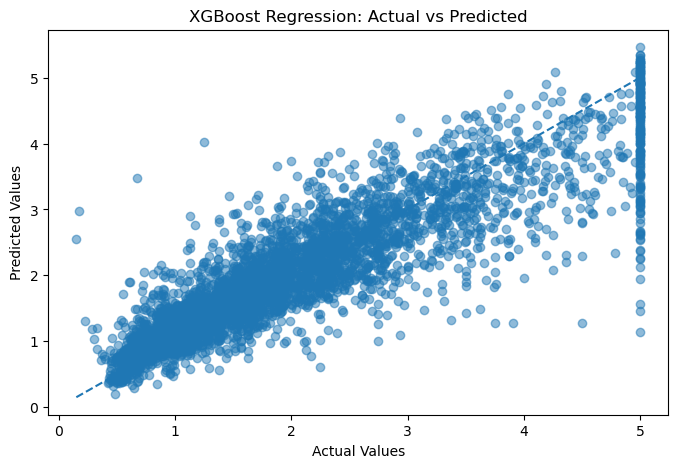

In [7]:
# XGBoost Regression Visualization
# Compare actual house prices with predicted house prices.

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("XGBoost Regression: Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

### xgboost implementation from scratch

In [8]:
# XGBoost Regression From Scratch
# Implement gradient, Hessian, split gain, leaf weights, and sequential boosting.

import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


class XGBoostTree:
    def __init__(self, max_depth=2, reg_lambda=1.0,
                 gamma=0.0, min_child_weight=1.0):
        self.max_depth = max_depth
        self.reg_lambda = reg_lambda
        self.gamma = gamma
        self.min_child_weight = min_child_weight

    def calculate_weight(self, G, H):
        return -G / (H + self.reg_lambda)

    def calculate_gain(self, GL, HL, GR, HR, G, H):
        left_score = (GL ** 2) / (HL + self.reg_lambda)
        right_score = (GR ** 2) / (HR + self.reg_lambda)
        parent_score = (G ** 2) / (H + self.reg_lambda)

        return 0.5 * (
            left_score + right_score - parent_score
        ) - self.gamma

    def find_best_split(self, X, gradients, hessians):
        best_gain = -float("inf")
        best_split = None

        G = np.sum(gradients)
        H = np.sum(hessians)

        n_samples, n_features = X.shape

        for feature in range(n_features):
            values = np.unique(X[:, feature])

            if len(values) < 2:
                continue

            thresholds = (values[:-1] + values[1:]) / 2

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask

                if not np.any(left_mask) or not np.any(right_mask):
                    continue

                GL = np.sum(gradients[left_mask])
                HL = np.sum(hessians[left_mask])

                GR = np.sum(gradients[right_mask])
                HR = np.sum(hessians[right_mask])

                if HL < self.min_child_weight or HR < self.min_child_weight:
                    continue

                gain = self.calculate_gain(
                    GL, HL, GR, HR, G, H
                )

                if gain > best_gain:
                    best_gain = gain
                    best_split = {
                        "feature": feature,
                        "threshold": threshold,
                        "left_mask": left_mask,
                        "gain": gain
                    }

        return best_split

    def build_tree(self, X, gradients, hessians, depth=0):
        G = np.sum(gradients)
        H = np.sum(hessians)

        # Default prediction if this node becomes a leaf
        leaf_weight = self.calculate_weight(G, H)

        node = {"value": leaf_weight}

        if depth >= self.max_depth:
            return node

        split = self.find_best_split(X, gradients, hessians)

        if split is None or split["gain"] <= 0:
            return node

        left_mask = split["left_mask"]
        right_mask = ~left_mask

        node = {
            "feature": split["feature"],
            "threshold": split["threshold"],
            "value": leaf_weight,
            "left": self.build_tree(
                X[left_mask],
                gradients[left_mask],
                hessians[left_mask],
                depth + 1
            ),
            "right": self.build_tree(
                X[right_mask],
                gradients[right_mask],
                hessians[right_mask],
                depth + 1
            )
        }

        return node

    def predict_row(self, row, node):
        if "feature" not in node:
            return node["value"]

        feature = node["feature"]
        threshold = node["threshold"]

        if row[feature] <= threshold:
            return self.predict_row(row, node["left"])

        return self.predict_row(row, node["right"])

    def predict(self, X):
        return np.array([
            self.predict_row(row, self.root)
            for row in X
        ])

    def fit(self, X, gradients, hessians):
        self.root = self.build_tree(X, gradients, hessians)
        return self


class XGBoostRegressorScratch:
    def __init__(self, n_estimators=10, learning_rate=0.1,
                 max_depth=2, reg_lambda=1.0,
                 gamma=0.0, min_child_weight=1.0):

        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.reg_lambda = reg_lambda
        self.gamma = gamma
        self.min_child_weight = min_child_weight

        self.trees = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        # Initial prediction: mean of target values
        self.base_prediction = np.mean(y)

        predictions = np.full(len(y), self.base_prediction)

        self.trees = []

        for iteration in range(self.n_estimators):

            # First derivative of squared-error loss
            gradients = predictions - y

            # Second derivative of squared-error loss
            hessians = np.ones(len(y))

            tree = XGBoostTree(
                max_depth=self.max_depth,
                reg_lambda=self.reg_lambda,
                gamma=self.gamma,
                min_child_weight=self.min_child_weight
            )

            tree.fit(X, gradients, hessians)

            # Update predictions using the new tree
            predictions += (
                self.learning_rate * tree.predict(X)
            )

            self.trees.append(tree)

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        predictions = np.full(
            len(X), self.base_prediction
        )

        for tree in self.trees:
            predictions += (
                self.learning_rate * tree.predict(X)
            )

        return predictions


# Load dataset
data = load_diabetes()

X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train custom XGBoost model
model = XGBoostRegressorScratch(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=2,
    reg_lambda=1.0,
    gamma=0.0,
    min_child_weight=1.0
)

model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Compare actual and predicted values
for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(f"Actual: {actual:.2f} | Predicted: {predicted:.2f}")

MAE: 42.98329490089927
MSE: 2800.416597407315
RMSE: 52.918962550368605
R2 Score: 0.4714351852622215
Actual: 219.00 | Predicted: 158.11
Actual: 70.00 | Predicted: 183.09
Actual: 202.00 | Predicted: 166.67
Actual: 230.00 | Predicted: 267.13
Actual: 111.00 | Predicted: 115.22
Actual: 84.00 | Predicted: 99.02
Actual: 242.00 | Predicted: 236.90
Actual: 272.00 | Predicted: 196.46
Actual: 94.00 | Predicted: 154.52
Actual: 96.00 | Predicted: 150.22
